<a href="https://colab.research.google.com/github/elhamod/BA305_Fall_2026/blob/main/Session%2019%20-%20MAKEUP%20FRI%20OCT%2030%20-%20FINAL%20PREP/final_prep_himalaya_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Final Practice: Planning a Himalayan Expedition — Solutions**

*Worked solutions. Try `final_prep_himalaya.ipynb` first, then compare your answers here. These are one reasonable set of choices; other choices can be defended too.*

You work for an agency that runs guided expeditions in the Nepal Himalaya. Before each season, operations has two planning questions:

1. **How many oxygen sets should we bring for an expedition?** A missing oxygen set high on the mountain costs the agency **10 times** what carrying a spare one does.
2. **Which climbers are at high risk of dying?**

**It is the end of 2014.** You build your models on the seasons 2000–2014, then see how they do on the next five (2015–2019).

**Practice, not graded.** Open this notebook in Colab (button above) and use **Gemini in Colab** for the code: click the Gemini (✦) button at the top right, or "Generate" in an empty code cell. Compare your results with your classmates': this is a friendly competition. Write the one-sentence answers yourself. On the Final you read output, you don't run code.

| Part | Topic | Time |
| --- | --- | --- |
| 1 | Know your data | ~20 min |
| 2 | Modeling and evaluation | ~20 min |
| 3 | Interpretation and drilling deeper | ~20 min |

**Data:** The Himalayan Database via TidyTuesday (2020-09-22): expeditions and climbers on Nepal's peaks, 1905–2019.

## Setup *(just run these cells)*

In [1]:
# Tools
import pandas as pd

# Load the three Himalayan Database files
url = 'https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2020/2020-09-22/'
members = pd.read_csv(url + 'members.csv')
exps = pd.read_csv(url + 'expeditions.csv')
peaks = pd.read_csv(url + 'peaks.csv')

In [2]:
# Expedition table: one row per expedition, ending with the number of oxygen sets its climbers used.

# Per expedition, count from the climber list: team size, hired staff, and climbers who used oxygen.
# (One expedition ID is used twice, so expeditions are matched on ID and year.)
key = ['expedition_id', 'year']
team = members.groupby(key).agg(team_size=('member_id', 'count'),
                                hired_staff=('hired', 'sum'),
                                o2_sets=('oxygen_used', 'sum')).reset_index()

# Height of each peak
peak_height = peaks[['peak_id', 'height_metres']].rename(columns={'height_metres': 'peak_height_metres'})

# Join the expedition details, the peak height and the counts
expeditions = exps[['expedition_id', 'peak_id', 'year', 'season', 'basecamp_date', 'termination_date',
                    'oxygen_used', 'termination_reason']]
expeditions = expeditions.merge(peak_height, on='peak_id', how='left').merge(team, on=key)

# Put the columns in order, with the target last
expeditions = expeditions[['expedition_id', 'peak_id', 'year', 'season', 'basecamp_date', 'termination_date',
                           'peak_height_metres', 'team_size', 'hired_staff', 'oxygen_used', 'termination_reason',
                           'o2_sets']]

# Turn the date text into real dates
expeditions['basecamp_date'] = pd.to_datetime(expeditions['basecamp_date'])
expeditions['termination_date'] = pd.to_datetime(expeditions['termination_date'])
expeditions

,expedition_id,peak_id,year,season,basecamp_date,termination_date,peak_height_metres,team_size,hired_staff,oxygen_used,termination_reason,o2_sets
0,ANN260101,ANN2,1960,Spring,1960-03-15,NaT,7937.0,19,9,True,Success (main peak),3
1,ANN269301,ANN2,1969,Autumn,1969-09-25,1969-10-26,7937.0,10,0,False,Success (main peak),0
2,ANN273101,ANN2,1973,Spring,1973-03-16,NaT,7937.0,6,0,False,Success (main peak),0
3,ANN278301,ANN2,1978,Autumn,1978-09-08,1978-10-05,7937.0,2,0,False,"Bad weather (storms, high winds)",0
4,ANN279301,ANN2,1979,Autumn,NaT,1979-10-20,7937.0,3,0,False,"Bad weather (storms, high winds)",0
...,...,...,...,...,...,...,...,...,...,...,...,...
10346,PUMO19101,PUMO,2019,Spring,2019-04-04,2019-05-27,7138.0,11,3,False,Success (main peak),0
10347,PUMO19102,PUMO,2019,Spring,2019-04-14,2019-05-25,7138.0,2,1,False,Success (main peak),0
10348,PUTH19101,PUTH,2019,Spring,2019-05-09,2019-05-17,7246.0,7,2,False,"Bad conditions (deep snow, avalanching, fallin...",0
10349,RATC19101,RATC,2019,Spring,2019-04-11,2019-05-03,7035.0,1,0,False,Lack (or loss) of supplies or equipment,0


In [3]:
# Climber table: one row per climber, ending with whether they died

# Add the height of the peak each climber attempted
climbers = members.merge(peak_height, on='peak_id', how='left')

# Keep these columns, with the target last
climbers = climbers[['member_id', 'peak_id', 'year', 'season', 'sex', 'age', 'citizenship', 'hired',
                     'peak_height_metres', 'highpoint_metres', 'death_cause', 'died']]
climbers

,member_id,peak_id,year,season,sex,age,citizenship,hired,peak_height_metres,highpoint_metres,death_cause,died
0,AMAD78301-01,AMAD,1978,Autumn,M,40.0,France,False,6814.0,NaN,NaN,False
1,AMAD78301-02,AMAD,1978,Autumn,M,41.0,France,False,6814.0,6000.0,NaN,False
2,AMAD78301-03,AMAD,1978,Autumn,M,27.0,France,False,6814.0,NaN,NaN,False
3,AMAD78301-04,AMAD,1978,Autumn,M,40.0,France,False,6814.0,6000.0,NaN,False
4,AMAD78301-05,AMAD,1978,Autumn,M,34.0,France,False,6814.0,NaN,NaN,False
...,...,...,...,...,...,...,...,...,...,...,...,...
76514,PUTH19101-07,PUTH,2019,Spring,M,44.0,Nepal,True,7246.0,6350.0,NaN,False
76515,RATC19101-01,RATC,2019,Spring,M,55.0,Romania,False,7035.0,6600.0,NaN,False
76516,SANK19101-01,SANK,2019,Spring,M,56.0,Austria,False,6452.0,6452.0,NaN,False
76517,SANK19101-02,SANK,2019,Spring,F,57.0,Austria,False,6452.0,5700.0,NaN,False


In [4]:
# Train on the seasons 2000-2014; test on the next five (2015-2019)
TRAIN_START_YEAR = 2000
TEST_START_YEAR = 2015

### What each column means

**`expeditions`** — one row per expedition

| Column | Meaning |
| --- | --- |
| `expedition_id` | Code for the expedition |
| `peak_id` | Code for the peak (for example `EVER` = Everest) |
| `year`, `season` | When the expedition took place |
| `basecamp_date` | Date the team reached base camp |
| `termination_date` | Date the expedition ended |
| `peak_height_metres` | Height of the peak |
| `team_size` | Number of climbers listed on the expedition, hired staff included |
| `hired_staff` | Number of listed climbers who were hired staff (for example Sherpa guides) |
| `oxygen_used` | Whether anyone on the expedition used bottled oxygen |
| `termination_reason` | Why the expedition ended (reached the summit, bad weather, an accident, ...) |
| `o2_sets` | **Target for Question 3:** number of listed climbers who used bottled oxygen |

**`climbers`** — one row per climber on an expedition

| Column | Meaning |
| --- | --- |
| `member_id` | Code for the climber on that expedition |
| `peak_id`, `year`, `season`, `peak_height_metres` | Same as in `expeditions` |
| `sex`, `age`, `citizenship` | The climber |
| `hired` | Whether the climber was hired staff rather than a paying client |
| `highpoint_metres` | Highest point the climber reached |
| `death_cause` | Cause of death, for climbers who died |
| `died` | **Target for Question 4:** whether the climber died on the expedition |

# **Part 1: Know your data** (~20 min)

Missing values, duplicates and distinct values, already counted for you:

In [5]:
# For each table: rows, exact duplicate rows, and per column the type, missing values and distinct values
for name, table in [('expeditions', expeditions), ('climbers', climbers)]:
    # Rows and exact duplicates
    print(f'{name}: {len(table)} rows, {table.duplicated().sum()} exact duplicate rows')
    # Type, missing values and distinct values of each column
    display(pd.DataFrame({'type': table.dtypes, 'missing': table.isna().sum(), 'distinct': table.nunique()}))

expeditions: 10351 rows, 0 exact duplicate rows


,type,missing,distinct
expedition_id,str,0,10350
peak_id,str,0,391
year,int64,0,92
season,str,0,5
basecamp_date,datetime64[us],1082,4180
termination_date,datetime64[us],2367,3266
peak_height_metres,float64,1,353
team_size,int64,0,68
hired_staff,int64,0,34
oxygen_used,bool,0,2


climbers: 76519 rows, 0 exact duplicate rows


,type,missing,distinct
member_id,str,0,76518
peak_id,str,0,391
year,int64,0,92
season,str,0,5
sex,str,2,2
age,float64,3497,74
citizenship,str,10,212
hired,bool,0,2
peak_height_metres,float64,15,353
highpoint_metres,float64,21833,885


In [6]:
# Remove exact duplicate rows
expeditions = expeditions.drop_duplicates()
climbers = climbers.drop_duplicates()

# Rows left
print(len(expeditions), 'expeditions and', len(climbers), 'climbers left')

10351 expeditions and 76519 climbers left


In [7]:
# Tools used in the solutions
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, accuracy_score, recall_score, precision_score

### Question 1

Prepare both tables for modeling.

**1a.** Which columns will you remove before modeling, and why?

In [8]:
# Expeditions: remove the IDs, the dates, and the columns only known after the climb
o2 = expeditions.drop(columns=['expedition_id', 'peak_id', 'basecamp_date', 'termination_date',
                               'oxygen_used', 'termination_reason'])

# Climbers: remove the IDs, the many-valued citizenship, and the columns only known after the climb
death = climbers.drop(columns=['member_id', 'peak_id', 'citizenship', 'highpoint_metres', 'death_cause'])

**Decision**

- **IDs** (`expedition_id`, `member_id`): removed, because they label rows rather than describe them.
- **Known only after the climb** (`oxygen_used` flag, `termination_reason`, `termination_date`, `death_cause`, `highpoint_metres`): removed, because the agency won't have them when planning.
- **`basecamp_date`, `peak_id`, `citizenship`:** removed to keep things simple; keeping them would also be reasonable.
- **`year`:** used only to split training years from test years, not as an input.

**1b.** What will you do with the missing values?

In [9]:
# Rows from the training years (2000-2014)
train_years = (death['year'] >= TRAIN_START_YEAR) & (death['year'] < TEST_START_YEAR)

# Missing age: fill with the median age of the training years
# (dropping these rows would also work; filling keeps the deaths among them)
death['age'] = death['age'].fillna(death.loc[train_years, 'age'].median())

# Drop the few rows still missing a value (a peak height or a sex)
o2 = o2.dropna()
death = death.dropna()
print(len(o2), 'expeditions and', len(death), 'climbers left')

10350 expeditions and 76502 climbers left


**Decision**

- Filled missing ages with the median age of the training years; dropping those rows would also have worked.
- Dropped the few rows still missing a peak height or a sex.

**1c. Custom cell.** Any other preparation you decide on (for example, turning text columns into dummy variables).

In [10]:
# Expeditions: turn season into 0/1 dummy columns
o2 = pd.get_dummies(o2, columns=['season'], drop_first=True)
print(list(o2.columns))

# Climbers: turn season and sex into 0/1 dummy columns
death = pd.get_dummies(death, columns=['season', 'sex'], drop_first=True)
print(list(death.columns))

['year', 'peak_height_metres', 'team_size', 'hired_staff', 'o2_sets', 'season_Spring', 'season_Summer', 'season_Unknown', 'season_Winter']
['year', 'age', 'hired', 'peak_height_metres', 'died', 'season_Spring', 'season_Summer', 'season_Winter', 'sex_M']


**Decision**

Turned `season` and `sex` into 0/1 dummy columns, because the models need numbers.

### Question 2

Which climbers and expeditions does this data describe well, and which hardly at all? Figures could help.

**A prompt to start from** (paste it into Gemini, then follow up on what you see):

> *"Make bar charts or histograms of sex, hired staff, season, highest point reached, cause of death, and oxygen sets used. Which groups are barely there, and what does that mean for whom a model will work?"*

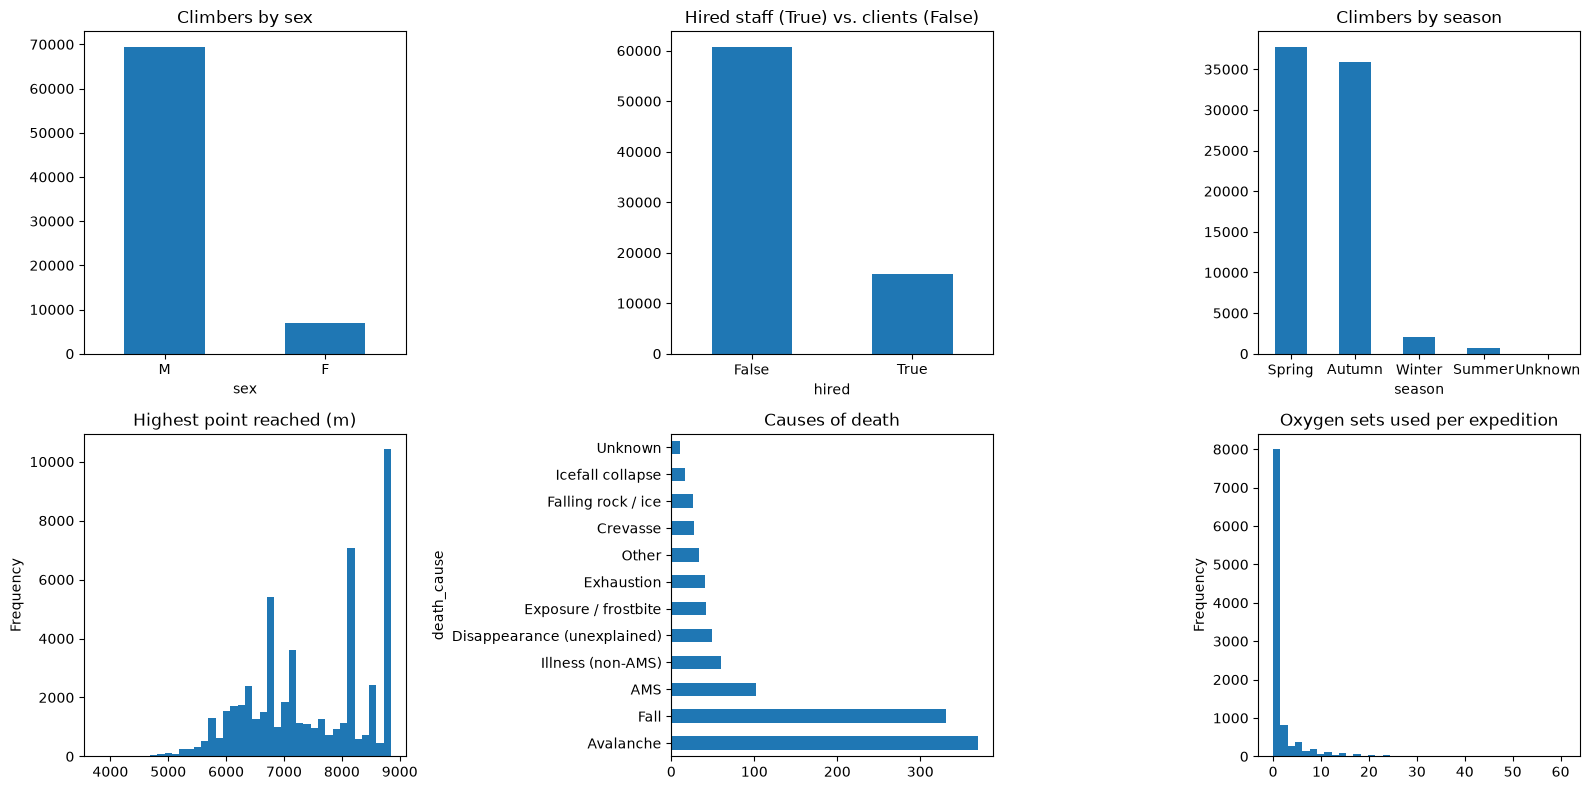

In [11]:
# A grid of six charts
fig, axes = plt.subplots(2, 3, figsize=(16, 8))

# Who the climbers are: sex, hired staff or client, season
climbers['sex'].value_counts().plot.bar(ax=axes[0, 0], rot=0, title='Climbers by sex')
climbers['hired'].value_counts().plot.bar(ax=axes[0, 1], rot=0, title='Hired staff (True) vs. clients (False)')
climbers['season'].value_counts().plot.bar(ax=axes[0, 2], rot=0, title='Climbers by season')

# How climbs end: highest point reached, causes of death
climbers['highpoint_metres'].plot.hist(bins=40, ax=axes[1, 0], title='Highest point reached (m)')
climbers['death_cause'].value_counts().plot.barh(ax=axes[1, 1], title='Causes of death')

# Oxygen sets used per expedition
expeditions['o2_sets'].plot.hist(bins=40, ax=axes[1, 2], title='Oxygen sets used per expedition')
plt.tight_layout()
plt.show()

**Answer**

- Most climbers are **men**, and most are **paying clients** rather than hired staff.
- Almost all climbs happen in **spring and autumn**; winter and summer are rare.
- Most deaths come from **avalanches and falls**.
- Most expeditions use **no oxygen at all**, and a few use dozens of sets.
- A model will know little about the rare groups, such as women and winter or summer climbers.

# **Part 2: Modeling and evaluation** (~20 min)

**How an oxygen plan is scored.** A plan says how many oxygen sets to bring on each expedition, and it can go wrong in two ways:

- **Too few sets:** a climber goes without oxygen high on the mountain.
- **Too many sets:** money is spent, and porters carry weight for nothing.

The agency judges a missing set **10 times** as bad as a spare one. These costs are hypothetical: you can read them as dollars, but they also stand for things that are hard to price, such as a climber's safety or the agency's reputation. The function below adds up the cost of a plan over all expeditions. **Lower is better.**

In [12]:
# Tool for scoring your oxygen plans (just run this cell)
# Question 3 - the total cost of an oxygen plan over all expeditions:
#   brought: sets the agency brings; actual: sets the climbers needed
#   - brought_cost: cost of each spare set (brought but not needed): money, and weight porters carry for nothing
#   - missing_cost: cost of each missing set (needed but not brought): a climber goes without oxygen high up.
#     The agency judges a missing set 10 times worse than a spare one, so missing_cost=10 and brought_cost=1.
# These costs are hypothetical. You can read them as dollars, but they can also stand for things that are hard
# to price, such as a climber's safety or the agency's reputation. What matters is how they compare (10 to 1).
def oxygen_cost(brought, actual, missing_cost=10, brought_cost=1):
    # Sets missing and sets spare, per expedition
    missing = (actual - brought).clip(lower=0)   # sets that were needed but not brought
    spare = (brought - actual).clip(lower=0)     # sets carried for nothing

    # Total cost over all expeditions
    cost = missing_cost * missing.sum() + brought_cost * spare.sum()

    # Report in plain words, one fact per line
    print('---')
    print(f'Expeditions with not enough oxygen: {(missing > 0).sum():,} of {len(actual):,} ({(missing > 0).mean():.0%})')
    print(f'Sets missing in total: {missing.sum():,.0f}')
    print(f'Spare sets carried but not needed, in total: {spare.sum():,.0f}')
    print(f'Spare sets per expedition, on average: {spare.mean():.1f}')
    print(f'Total cost of this plan: {cost:,.0f}')
    print('---')
    return cost

### Question 3

How many oxygen sets should the agency bring on each 2015–2019 expedition? Compare at most two models, at least one of them easy to interpret. Can you beat a dummy model that brings the same number of sets to every expedition, according to the `oxygen_cost` function above?

In [13]:
# Training rows: 2000-2014; test rows: 2015-2019
train_rows = (o2['year'] >= TRAIN_START_YEAR) & (o2['year'] < TEST_START_YEAR)
o2_train, o2_test = o2[train_rows], o2[o2['year'] >= TEST_START_YEAR]

# Inputs and target (year is only used for the split, not as an input)
X_train, y_train = o2_train.drop(columns=['o2_sets', 'year']), o2_train['o2_sets']
X_test, y_test = o2_test.drop(columns=['o2_sets', 'year']), o2_test['o2_sets']

In [14]:
# Dummy model (the baseline): bring the training average to every expedition.
# There may be better baselines, such as one set per team member, but we will not try them here.
dummy = DummyRegressor(strategy='mean').fit(X_train, y_train)

# Its cost on 2015-2019
dummy_cost = oxygen_cost(dummy.predict(X_test), y_test)

---
Expeditions with not enough oxygen: 548 of 1,497 (37%)
Sets missing in total: 4,180
Spare sets carried but not needed, in total: 1,739
Spare sets per expedition, on average: 1.2
Total cost of this plan: 43,538
---


In [15]:
# Model 1 - linear regression
linear_o2 = LinearRegression().fit(X_train, y_train)

# Coefficients: extra sets per unit of each input, smallest to largest
print(pd.Series(linear_o2.coef_, index=X_train.columns).sort_values().round(3))

# Its cost on 2015-2019
linear_cost = oxygen_cost(linear_o2.predict(X_test), y_test)

season_Unknown        0.000
peak_height_metres    0.001
team_size             0.180
season_Winter         0.261
season_Summer         0.318
season_Spring         0.803
hired_staff           1.081
dtype: float64
---
Expeditions with not enough oxygen: 870 of 1,497 (58%)
Sets missing in total: 1,662
Spare sets carried but not needed, in total: 2,054
Spare sets per expedition, on average: 1.4
Total cost of this plan: 18,670
---


In [16]:
# Model 2 - regression tree: settings to try
grid = {'max_depth': [2, 4, 6, 8, 10], 'min_samples_leaf': [5, 20, 50, 100]}

# Tune with 5-fold cross-validation (folds shuffled: the rows are sorted by peak)
search = GridSearchCV(DecisionTreeRegressor(random_state=1), grid, scoring='neg_mean_absolute_error',
                      cv=KFold(n_splits=5, shuffle=True, random_state=1)).fit(X_train, y_train)
tree_o2 = search.best_estimator_
print('Best settings:', search.best_params_)

# Average error in sets: training vs. cross-validated
print('Average error (sets) - train', round(mean_absolute_error(y_train, tree_o2.predict(X_train)), 2),
      '| cross-validated', round(-search.best_score_, 2))

# Its cost on 2015-2019
tree_cost = oxygen_cost(tree_o2.predict(X_test), y_test)

Best settings: {'max_depth': 10, 'min_samples_leaf': 5}
Average error (sets) - train 0.66 | cross-validated 0.81
---
Expeditions with not enough oxygen: 479 of 1,497 (32%)
Sets missing in total: 1,099
Spare sets carried but not needed, in total: 1,233
Spare sets per expedition, on average: 0.8
Total cost of this plan: 12,225
---


In [17]:
# Compare the plans on 2015-2019 (lower is better)
pd.Series({'Dummy model': dummy_cost, 'Linear regression': linear_cost, 'Regression tree': tree_cost}).sort_values().round(0)

Regression tree      12225.0
Linear regression    18670.0
Dummy model          43538.0
dtype: float64

**Answer**

**Yes.**

- The **regression tree** costs the least (12,225), far below the dummy model (43,538).
- **Linear regression** also beats the dummy (18,670), but a straight line fits badly because most expeditions use no oxygen and a few use many.
- Even the tree leaves 32% of expeditions without enough oxygen, which is costly because each missing set counts 10 times.

### Question 4

Predict which climbers on 2015–2019 expeditions will die (`died`). Compare at most two models, at least one of them easy to interpret. The agency has decided to **catch as many deaths as possible, without flagging so many climbers that the warning means nothing**. Decide where to draw the line between "high risk" and not, and defend that choice to the agency.

In [19]:
# Training rows: 2000-2014; test rows: 2015-2019
train_rows = (death['year'] >= TRAIN_START_YEAR) & (death['year'] < TEST_START_YEAR)
d_train, d_test = death[train_rows], death[death['year'] >= TEST_START_YEAR]

# Inputs and target (year is only used for the split, not as an input)
Xd_train, yd_train = d_train.drop(columns=['died', 'year']), d_train['died']
Xd_test, yd_test = d_test.drop(columns=['died', 'year']), d_test['died']

# Scale the inputs to 0-1
scale_d = MinMaxScaler()
Xd_train_s, Xd_test_s = scale_d.fit_transform(Xd_train), scale_d.transform(Xd_test)

# Death rate among all 2015-2019 climbers: flagging at random would give this precision
print(f'Death rate 2015-2019: {yd_test.mean():.2%} of all climbers')

Death rate 2015-2019: 0.75% of all climbers


In [20]:
# Dummy model: always guess "survives"
dummy_d = DummyClassifier(strategy='most_frequent').fit(Xd_train_s, yd_train)
pred = dummy_d.predict(Xd_test_s)

# Very accurate, but it catches no deaths
print('Accuracy:', round(accuracy_score(yd_test, pred), 3))
# Recall and precision on 2015-2019, one per line
print('---')
print(f'Recall: {recall_score(yd_test, pred):.0%} of the climbers who died had been flagged as high risk')
print(f'Precision: {precision_score(yd_test, pred, zero_division=0):.2%} of flagged climbers died')
print('---')

Accuracy: 0.993
---
Recall: 0% of the climbers who died had been flagged as high risk
Precision: 0.00% of flagged climbers died
---


In [21]:
# Model 1 - logistic regression (class_weight makes each death count more)
logit = LogisticRegression(class_weight='balanced', max_iter=1000).fit(Xd_train_s, yd_train)

# Predict with the default cutoff 0.5
pred = logit.predict(Xd_test_s)

# Recall and precision on 2015-2019, one per line
print('---')
print(f'Recall: {recall_score(yd_test, pred):.0%} of the climbers who died had been flagged as high risk')
print(f'Precision: {precision_score(yd_test, pred, zero_division=0):.2%} of flagged climbers died')
print('---')

---
Recall: 68% of the climbers who died had been flagged as high risk
Precision: 0.82% of flagged climbers died
---


In [22]:
# Model 2 - decision tree (class_weight makes each death count more)
tree_d = DecisionTreeClassifier(class_weight='balanced', max_depth=5, min_samples_leaf=100,
                                random_state=1).fit(Xd_train_s, yd_train)

# Predict with the default cutoff 0.5
pred = tree_d.predict(Xd_test_s)

# Recall and precision on 2015-2019, one per line
print('---')
print(f'Recall: {recall_score(yd_test, pred):.0%} of the climbers who died had been flagged as high risk')
print(f'Precision: {precision_score(yd_test, pred, zero_division=0):.2%} of flagged climbers died')
print('---')

---
Recall: 70% of the climbers who died had been flagged as high risk
Precision: 0.87% of flagged climbers died
---


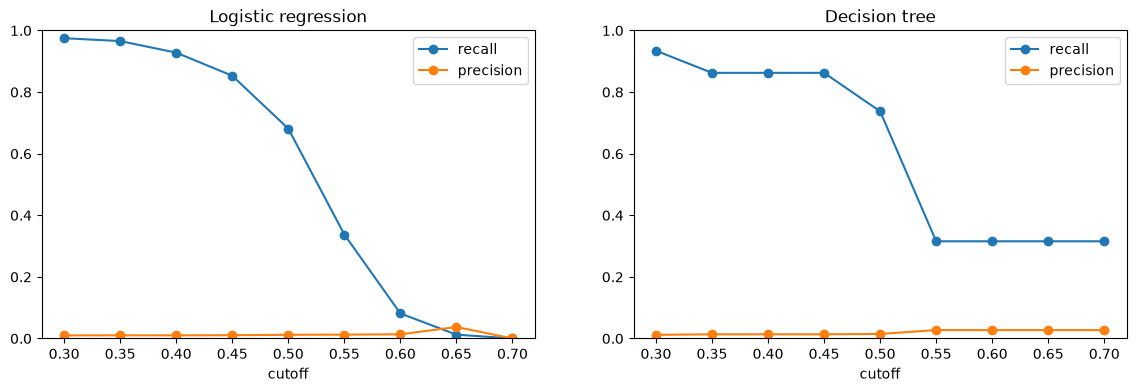

In [24]:
# Recall and precision of both models at a range of cutoffs, on the TRAINING years
# (the cutoff is chosen before looking at 2015-2019)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, model) in zip(axes, [('Logistic regression', logit), ('Decision tree', tree_d)]):
    # Each training climber's predicted probability of dying
    prob = model.predict_proba(Xd_train_s)[:, 1]

    # Recall and precision at each cutoff
    rows = []
    for cutoff in np.arange(0.30, 0.71, 0.05):
        pred = prob >= cutoff
        rows.append({'cutoff': round(cutoff, 2), 'recall': recall_score(yd_train, pred),
                     'precision': precision_score(yd_train, pred, zero_division=0)})

    # Plot both on the same 0-1 scale
    pd.DataFrame(rows).set_index('cutoff').plot(ax=ax, marker='o', ylim=(0, 1), title=name)
plt.show()

In [25]:
# Chosen by eye from the plots: the decision tree at cutoff 0.5 (above 0.5 its recall collapses)
death_model, DEATH_CUTOFF = tree_d, 0.5

# How it does on 2015-2019
pred = death_model.predict_proba(Xd_test_s)[:, 1] >= DEATH_CUTOFF
# Recall and precision on 2015-2019, one per line
print('---')
print(f'Recall: {recall_score(yd_test, pred):.0%} of the climbers who died had been flagged as high risk')
print(f'Precision: {precision_score(yd_test, pred, zero_division=0):.2%} of flagged climbers died')
print('---')

---
Recall: 70% of the climbers who died had been flagged as high risk
Precision: 0.87% of flagged climbers died
---


**Answer**

- The dummy model is 99.3% accurate but catches no deaths, so accuracy is useless here.
- At cutoff 0.5, both models catch about 70% of deaths (logistic regression 68%, tree 70%).
- In the plots, raising the logistic regression's cutoff loses deaths without improving precision much.
- The tree keeps most of its recall up to 0.5 and loses it above, so I chose the tree at 0.5 (0.45 or 0.55 could also be defended).
- **Precision stays near zero at every cutoff:** even when we give up almost all the recall, it barely rises, so flagging a climber as high risk is little better than a shot in the dark.

# **Part 3: Interpretation and drilling deeper** (~20 min)

### Question 5

Which inputs matter most to your best model for each question, and how can you tell?

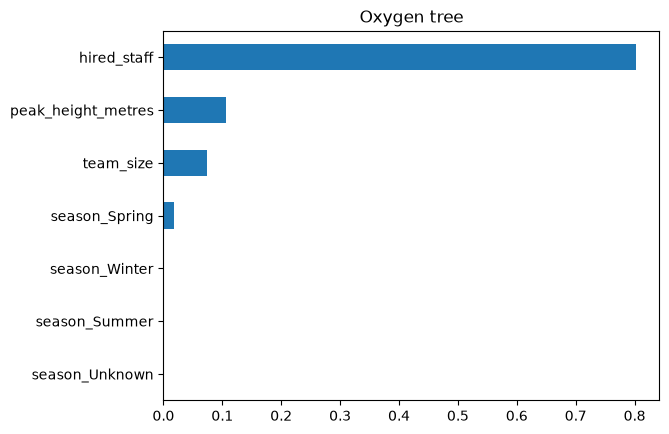

In [26]:
# Oxygen: what the tree splits on most
pd.Series(tree_o2.feature_importances_, index=X_train.columns).sort_values().plot.barh(title='Oxygen tree')
plt.show()

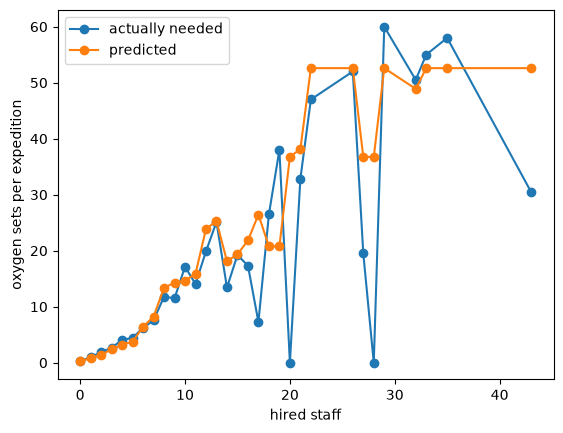

In [27]:
# Oxygen: sets actually needed and the tree's prediction, per expedition (2015-2019)
check = pd.DataFrame({'hired staff': X_test['hired_staff'], 'actually needed': y_test,
                      'predicted': tree_o2.predict(X_test)})

# Averages by number of hired staff
check.groupby('hired staff')[['actually needed', 'predicted']].mean().plot(marker='o')
plt.ylabel('oxygen sets per expedition')
plt.show()

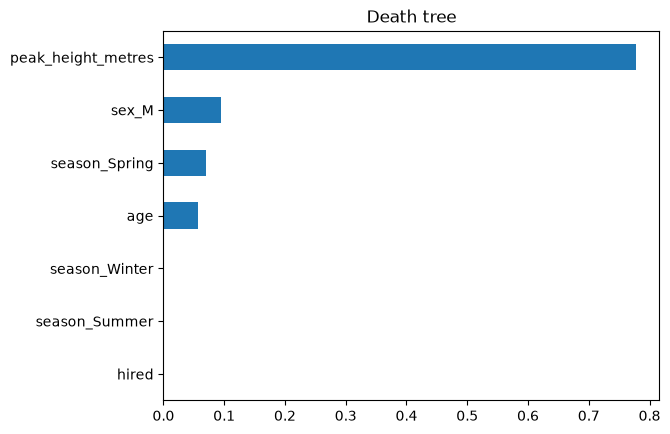

In [28]:
# Death: what the tree splits on most
pd.Series(tree_d.feature_importances_, index=Xd_train.columns).sort_values().plot.barh(title='Death tree')
plt.show()

In [29]:
# Death: odds ratios from the logistic regression (above 1 = riskier, below 1 = safer)
# Caution: an odds ratio resting on few deaths is unreliable. In 2000-2014 there were only 12 deaths
# among women, 2 in winter and none in summer.
pd.Series(np.exp(logit.coef_[0]), index=Xd_train.columns).sort_values().round(2)

season_Summer         0.03
season_Winter         0.55
season_Spring         1.02
hired                 1.38
peak_height_metres    1.77
sex_M                 2.62
age                   3.14
dtype: float64

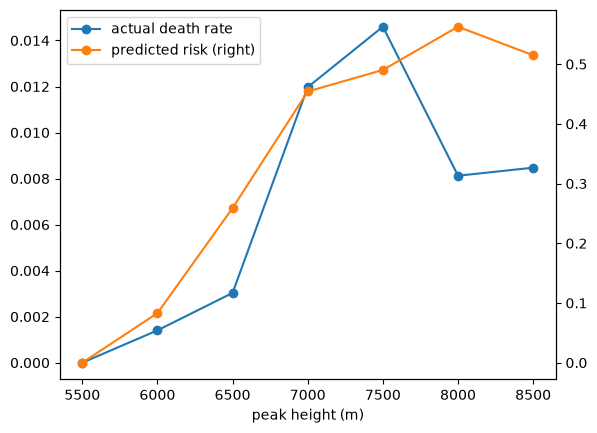

In [30]:
# Death: actual outcome and the tree's predicted risk, per climber, by peak height rounded down to 500 m (2015-2019)
check = pd.DataFrame({'peak height (m)': (d_test['peak_height_metres'] // 500) * 500,
                      'actual death rate': yd_test, 'predicted risk': death_model.predict_proba(Xd_test_s)[:, 1]})

# Averages by peak height (class_weight pushes all predicted risks up, so they get their own scale on the right)
check.groupby('peak height (m)')[['actual death rate', 'predicted risk']].mean().plot(marker='o', secondary_y='predicted risk')
plt.show()

**Answer**

- **Oxygen:** the tree relies mostly on **hired staff**: more hired staff, more oxygen.
- Its predictions follow actual use well up to about 15 hired staff; above that there are few expeditions.
- **Death:** the tree relies almost entirely on **peak height**.
- In the logistic regression, numbers above 1 mean higher risk: older climbers, men, higher peaks and hired staff are riskier.
- Some of these numbers rest on very few deaths (12 women, 2 in winter, none in summer), so they are not reliable.

### Question 6

Does your death model work equally well for women and men? Find out why.

In [31]:
# Which 2015-2019 climbers the death model flags
flagged = death_model.predict_proba(Xd_test_s)[:, 1] >= DEATH_CUTOFF

# For women and for men: climbers, flagged, died, and died after being flagged
for name, group in [('Women', (d_test['sex_M'] == 0).values), ('Men', (d_test['sex_M'] == 1).values)]:
    print(f'{name}: {group.sum()} climbers, {flagged[group].sum()} flagged as high risk, '
          f'{yd_test[group].sum()} died, {(flagged[group] & yd_test[group].values).sum()} of those who died had been flagged')

Women: 1388 climbers, 224 flagged as high risk, 5 died, 0 of those who died had been flagged
Men: 10916 climbers, 7126 flagged as high risk, 87 died, 64 of those who died had been flagged


In [32]:
# Death rate by sex, with and without hired staff
climbers.groupby(['hired', 'sex'])['died'].mean().unstack().round(4)

sex,F,M
hired,,
False,0.0070,0.0137
True,0.0312,0.0202


**Answer**

**No.**

- The model caught 64 of the 87 men who died, but none of the 5 women who died.
- It flags few women because, among paying clients, women die about half as often as men (0.70% vs. 1.37%).
- With only 5 deaths, we can't really judge the model for women.

### Question 7

Does your model hold up year by year after 2014? Explain what you see.

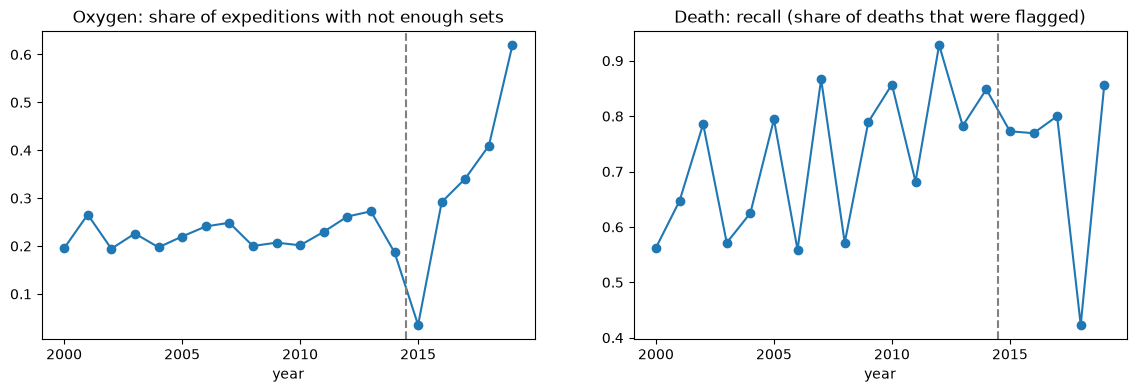

In [33]:
# Oxygen, every year from 2000: expeditions where the tree brings fewer sets than needed
o2_years = o2[o2['year'] >= TRAIN_START_YEAR]
not_enough = o2_years['o2_sets'] > tree_o2.predict(o2_years.drop(columns=['o2_sets', 'year']))

# Death, every year from 2000: which climbers are flagged, and who died
d_years = death[death['year'] >= TRAIN_START_YEAR]
flagged_all = death_model.predict_proba(scale_d.transform(d_years.drop(columns=['died', 'year'])))[:, 1] >= DEATH_CUTOFF
deaths = d_years['died'].values

# Two line charts: share with not enough oxygen, and recall, by year
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
not_enough.groupby(o2_years['year']).mean().plot(ax=axes[0], marker='o',
                                                 title='Oxygen: share of expeditions with not enough sets')
pd.Series(flagged_all[deaths], index=d_years['year'].values[deaths]).groupby(level=0).mean().plot(
    ax=axes[1], marker='o', title='Death: recall (share of deaths that were flagged)')

# Mark the split between training and test years
for ax in axes:
    ax.axvline(TEST_START_YEAR - 0.5, color='grey', linestyle='--')
    ax.set_xticks(range(2000, 2020, 5))
    ax.set_xlabel('year')
plt.show()

**Answer**

- **Oxygen:** after 2014, the share of expeditions without enough oxygen climbs to about 60% by 2019, because climbers used more oxygen than before.
- 2015 is an exception: the earthquake ended that season early.
- **Death:** the share of deaths caught jumps around before and after 2014, because each year has only a handful of deaths.
- The oxygen model should be retrained as behaviour changes.

### What this practice covered

| Final topic | Sessions | Where in this notebook |
| --- | --- | --- |
| Data preparation | 1, 18 | Question 1 |
| Charts that show who is in the data | 2–3 | Question 2 |
| Linear regression, regression trees | 12–13 | Question 3 |
| Logistic regression, decision trees | 12–13, 15 | Question 4 |
| Metrics, cutoffs, costs | 6–7, 18 | Questions 3–4 |
| Interpreting models, bias, drift | 13, 15, 18 | Questions 5–7 |